# RNN: recurrent network (GRU or LSTM)

An RNN reads a sequence one step at a time and keeps a memory of what it has seen. It is built for **sequences of events**, such as the flows from one source IP over time.

**Feasibility, and an honest caveat:** the training file (`UNSW_NB15_training-set.csv`) has **no IPs or timestamps**, so there are no real flow sequences to give an RNN. This notebook therefore treats the 45 features of **one flow** as a sequence of 45 steps. That runs and is common in papers, but the "sequence" is an artefact of column order, so the RNN's memory has nothing real to remember. It is also the slowest model here. Report it as a comparison model, and say clearly why it is not a natural fit.

A genuine RNN for this project would need sequences of flows per source IP, built from the raw four UNSW files or from live Zeek data. That changes the live pipeline too (it must buffer recent flows per source), so it is not done here.

Set `CELL = "lstm"` to use an LSTM instead of a GRU. Run after the preprocessing notebook.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 30              # early stopping usually ends training much sooner
PATIENCE = 8

CELL = "gru"          # "gru" (faster) or "lstm"
RNN_UNITS = 64
DENSE_UNITS = 32
DROPOUT = 0.3

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [5]:
keras.utils.set_random_seed(SEED)


def head(x, n_out, binary):
    if binary:
        return layers.Dense(1, activation="sigmoid")(x)
    return layers.Dense(n_out, activation="softmax")(x)


def compile_model(model, binary):
    if binary:
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc")]
    else:
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def fit_model(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Architecture

The 45 features are reshaped to 45 steps with 1 value each. A GRU (or LSTM) reads the steps and its final state goes through a Dense layer to the output.

In [6]:
def build_model(n_in, n_out, binary):
    Cell = layers.GRU if CELL == "gru" else layers.LSTM
    inputs = keras.Input(shape=(n_in,))
    x = layers.Reshape((n_in, 1))(inputs)
    x = Cell(RNN_UNITS)(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = layers.Dropout(DROPOUT)(x)
    return keras.Model(inputs, head(x, n_out, binary))

## 6. Binary model (normal vs attack)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
274/274 - 19s - 70ms/step - auc: 0.8515 - loss: 0.4655 - val_auc: 0.9445 - val_loss: 0.3305 - learning_rate: 0.0010
Epoch 2/30
274/274 - 13s - 47ms/step - auc: 0.9400 - loss: 0.2985 - val_auc: 0.9610 - val_loss: 0.2770 - learning_rate: 0.0010
Epoch 3/30
274/274 - 13s - 47ms/step - auc: 0.9492 - loss: 0.2755 - val_auc: 0.9666 - val_loss: 0.2627 - learning_rate: 0.0010
Epoch 4/30
274/274 - 13s - 46ms/step - auc: 0.9614 - loss: 0.2483 - val_auc: 0.9761 - val_loss: 0.2203 - learning_rate: 0.0010
Epoch 5/30
274/274 - 13s - 47ms/step - auc: 0.9672 - loss: 0.2299 - val_auc: 0.9781 - val_loss: 0.2129 - learning_rate: 0.0010
Epoch 6/30
274/274 - 13s - 46ms/step - auc: 0.9696 - loss: 0.2201 - val_auc: 0.9800 - val_loss: 0.2037 - learning_rate: 0.0010
Epoch 7/30
274/274 - 12s - 46ms/step - auc: 0.9714 - loss: 0.2123 - val_auc: 0.9807 - val_loss: 0.2088 - learning_rate: 0.0010
Epoch 8/30
274/274 - 13s - 46ms/step - auc: 0.9732 - loss: 0.2047 - val_auc: 0.9817 - val_loss: 0.2058 - learni

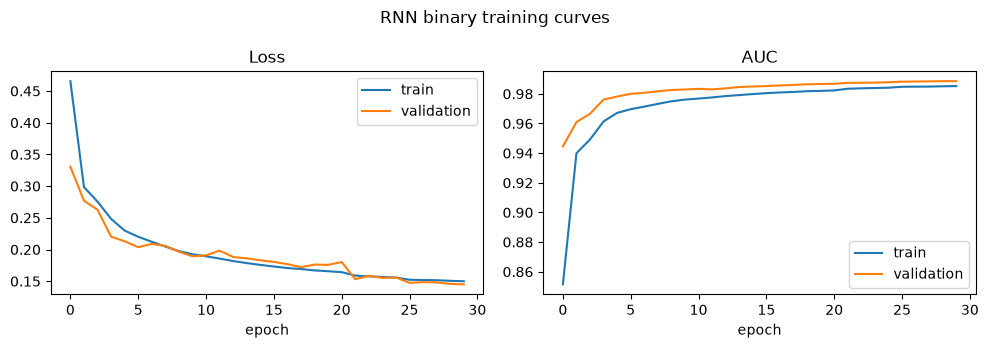

In [7]:
model_bin = compile_model(build_model(n_features, 1, True), True)
model_bin.summary()
hist_bin = fit_model(model_bin, X_train, yb_train, X_val, yb_val, cw_bin)
plot_history(hist_bin, "auc", "RNN binary training curves")

              precision    recall  f1-score   support

      Normal     0.8315    0.9560    0.8894     11200
      Attack     0.9778    0.9091    0.9422     23869

    accuracy                         0.9241     35069
   macro avg     0.9046    0.9325    0.9158     35069
weighted avg     0.9311    0.9241    0.9253     35069

ROC-AUC:              0.9888
False positive rate:  0.0440  (493 normal flows flagged as attacks)
False negative rate:  0.0909  (2170 attacks missed)


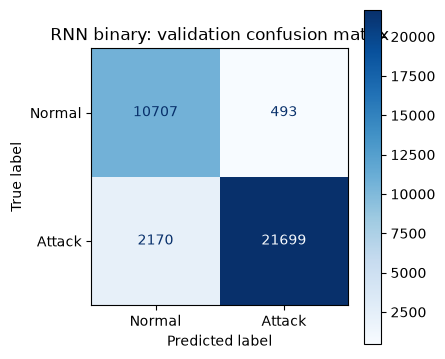

In [8]:
proba_bin = model_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)
row_bin = report_binary(
    yb_val, pred_bin, "RNN binary", score=proba_bin,
    ms=ms_per_1000(lambda X: model_bin.predict(X, batch_size=4096, verbose=0), X_val))

## 7. Multiclass model

Epoch 1/30
274/274 - 19s - 69ms/step - accuracy: 0.4055 - loss: 1.6379 - val_accuracy: 0.5675 - val_loss: 1.2498 - learning_rate: 0.0010
Epoch 2/30
274/274 - 18s - 66ms/step - accuracy: 0.5398 - loss: 1.2978 - val_accuracy: 0.5769 - val_loss: 1.1941 - learning_rate: 0.0010
Epoch 3/30
274/274 - 18s - 65ms/step - accuracy: 0.5850 - loss: 1.2393 - val_accuracy: 0.5925 - val_loss: 1.1706 - learning_rate: 0.0010
Epoch 4/30
274/274 - 18s - 66ms/step - accuracy: 0.6083 - loss: 1.2091 - val_accuracy: 0.6026 - val_loss: 1.1530 - learning_rate: 0.0010
Epoch 5/30
274/274 - 17s - 62ms/step - accuracy: 0.6225 - loss: 1.1908 - val_accuracy: 0.6095 - val_loss: 1.1381 - learning_rate: 0.0010
Epoch 6/30
274/274 - 18s - 64ms/step - accuracy: 0.6305 - loss: 1.1671 - val_accuracy: 0.6191 - val_loss: 1.1249 - learning_rate: 0.0010
Epoch 7/30
274/274 - 18s - 65ms/step - accuracy: 0.6388 - loss: 1.1503 - val_accuracy: 0.6350 - val_loss: 1.1021 - learning_rate: 0.0010
Epoch 8/30
274/274 - 18s - 64ms/step - ac

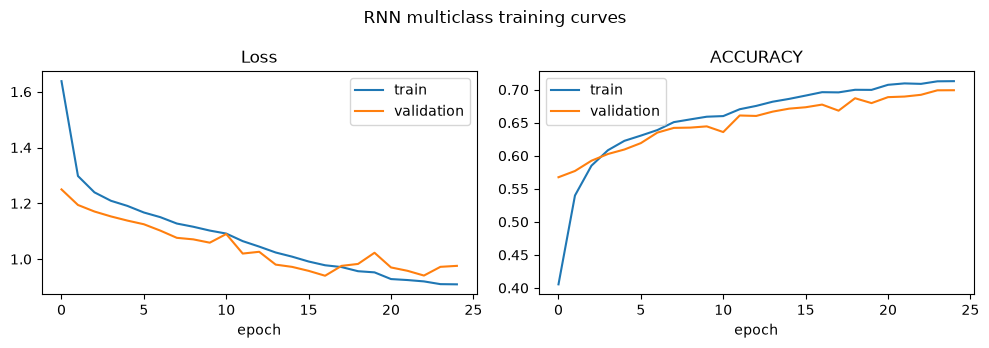

In [9]:
model_multi = compile_model(build_model(n_features, n_classes, False), False)
hist_multi = fit_model(model_multi, X_train, ym_train, X_val, ym_val, cw_multi)
plot_history(hist_multi, "accuracy", "RNN multiclass training curves")

                precision    recall  f1-score   support

        Normal     0.9530    0.5960    0.7334     11200
           DoS     0.2429    0.7799    0.3704      2453
Reconnaissance     0.6676    0.7732    0.7166      2099
       Fuzzers     0.5500    0.7314    0.6279      3637
      Exploits     0.7228    0.4435    0.5497      6678
       Generic     0.9988    0.9684    0.9834      8000
         Other     0.1640    0.1747    0.1692      1002

      accuracy                         0.6774     35069
     macro avg     0.6142    0.6381    0.5929     35069
  weighted avg     0.7885    0.6774    0.7020     35069

macro F1:    0.5929
weighted F1: 0.7020


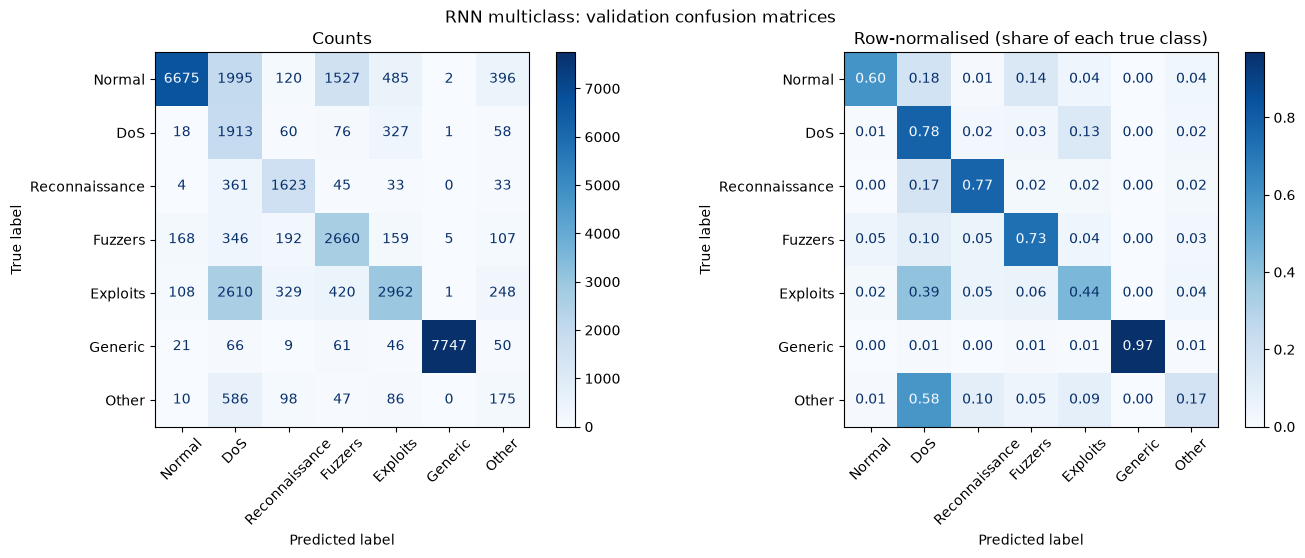

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,40.40,59.60
1,DoS,2453,99.27,77.99
2,Reconnaissance,2099,99.81,77.32
3,Fuzzers,3637,95.38,73.14
4,Exploits,6678,98.38,44.35
5,Generic,8000,99.74,96.84
6,Other,1002,99.00,17.47


In [10]:
pred_multi = model_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
row_multi = report_multiclass(
    ym_val, pred_multi, "RNN multiclass",
    ms=ms_per_1000(lambda X: model_multi.predict(X, batch_size=4096, verbose=0), X_val))

## 8. Save the models and compare with the other notebooks

Check `ms_per_1000_flows` in the table. The RNN is the slowest neural model here, so it is unlikely to be your live model.

In [11]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

model_bin.save(mdir / "rnn_binary.keras")
model_multi.save(mdir / "rnn_multiclass.keras")
pd.DataFrame([row_bin, row_multi]).to_csv(mdir / "rnn_validation_summary.csv", index=False)
for f in sorted(mdir.glob("rnn_*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e3:9.1f} KB")

rnn_binary.keras                     216.3 KB
rnn_multiclass.keras                 218.4 KB
rnn_validation_summary.csv             0.2 KB


In [12]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,CNN binary,0.9757,0.9403,0.9577,0.0499,24.1
4,CNN multiclass (macro),0.7158,0.7336,0.7000,NaN,21.0
5,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
6,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
7,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
8,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
9,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
